In [13]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv, find_dotenv

In [14]:
load_dotenv(find_dotenv())


model = ChatGroq(model="qwen/qwen3.8-27b")

In [15]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [ ]:
def generate_joke(state: JokeState):
    prompt = f'generate a joke on the topic: {state["topic"]}'
    response = model.invoke(prompt)
    return {"joke": response.content}

def generate_explanation(state:JokeState):
    prompt = f'write an explanation for the joke:\n{state["joke"]}'
    response = model.invoke(prompt)
    return {"explanation": response.content}

In [17]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

In [18]:
config1 = {"configurable": {"thread_id": "user1"}}
workflow.invoke({"topic": "neutrinos"}, config=config1)

{'topic': 'neutrinos',
 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."',
 'explanation': 'This joke is a play on words that combines two different meanings of the word **"ghost"** and relies on the unique physical properties of a specific subatomic particle called a **neutrino**.\n\nHere’s a breakdown of why it’s funny:\n\n### 1. The Double Meaning of "Ghost"\n*   **In the first line:** The bartender says, "We don’t serve **ghosts** here." In this context, he means **spirits of the dead** (supernatural entities).\n*   **In the punchline:** The bartender says, "I told you, **they’re** impossible to catch." Here, "they" refers back to the neutrino, but the word "ghost" has shifted in meaning to **"ghost particle"**—a nickname for neutri

In [19]:
list(workflow.get_state(config=config1))

[{'topic': 'neutrinos',
  'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."',
  'explanation': 'This joke is a play on words that combines two different meanings of the word **"ghost"** and relies on the unique physical properties of a specific subatomic particle called a **neutrino**.\n\nHere’s a breakdown of why it’s funny:\n\n### 1. The Double Meaning of "Ghost"\n*   **In the first line:** The bartender says, "We don’t serve **ghosts** here." In this context, he means **spirits of the dead** (supernatural entities).\n*   **In the punchline:** The bartender says, "I told you, **they’re** impossible to catch." Here, "they" refers back to the neutrino, but the word "ghost" has shifted in meaning to **"ghost particle"**—a nickname for neu

In [20]:
list(workflow.get_state_history(config=config1))

[StateSnapshot(values={'topic': 'neutrinos', 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."', 'explanation': 'This joke is a play on words that combines two different meanings of the word **"ghost"** and relies on the unique physical properties of a specific subatomic particle called a **neutrino**.\n\nHere’s a breakdown of why it’s funny:\n\n### 1. The Double Meaning of "Ghost"\n*   **In the first line:** The bartender says, "We don’t serve **ghosts** here." In this context, he means **spirits of the dead** (supernatural entities).\n*   **In the punchline:** The bartender says, "I told you, **they’re** impossible to catch." Here, "they" refers back to the neutrino, but the word "ghost" has shifted in meaning to **"ghost particle"**—a

## Time Travel

In [21]:
workflow.get_state({"configurable":{"thread_id":"user1", "checkpoint_id":"1f1d5706-59fe-6a36-8001-f9cb90490fca"}})

StateSnapshot(values={'topic': 'neutrinos', 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."'}, next=('generate_explanation',), config={'configurable': {'thread_id': 'user1', 'checkpoint_id': '1f1d5706-59fe-6a36-8001-f9cb90490fca'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-31T21:16:54.322824+00:00', parent_config={'configurable': {'thread_id': 'user1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5706-5733-6cde-8000-af394074b9b7'}}, tasks=(PregelTask(id='5b78ef13-4421-6062-acaa-0d6522c45042', name='generate_explanation', path=('__pregel_pull', 'generate_explanation'), error=None, interrupts=(), state=None, result={'topic': 'neutrinos', 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and s

In [29]:
workflow.invoke(None, {"configurable":{"thread_id":"user1", "checkpoint_id":"1f1d5706-59fe-6a36-8001-f9cb90490fca"}})
# starts from the 2nd node and generates the explaination again

{'topic': 'neutrinos',
 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."',
 'explanation': 'This joke is a clever wordplay based on the dual nature of the word **"ghosts"** and the physical properties of **neutrinos**. Here is the breakdown:\n\n### 1. The Scientific Premise\nNeutrinos are subatomic particles that interact extremely weakly with matter. They can pass through light-years of solid lead without being stopped. In physics, they are often described as "ghostly" because:\n- They have no electric charge.\n- They have very little mass.\n- They are incredibly difficult to detect or "catch" (detecting one requires massive underground detectors and takes years to see just a few).\n\n### 2. The Wordplay: "Ghosts"\nThe joke hinges on t

In [30]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'neutrinos', 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."', 'explanation': 'This joke is a clever wordplay based on the dual nature of the word **"ghosts"** and the physical properties of **neutrinos**. Here is the breakdown:\n\n### 1. The Scientific Premise\nNeutrinos are subatomic particles that interact extremely weakly with matter. They can pass through light-years of solid lead without being stopped. In physics, they are often described as "ghostly" because:\n- They have no electric charge.\n- They have very little mass.\n- They are incredibly difficult to detect or "catch" (detecting one requires massive underground detectors and takes years to see just a few).\n\n### 2. The Wordplay: "Ghosts"\n

## Updating State

In [ ]:
workflow.update_state({"configurable":{"thread_id":"user1", 'checkpoint_ns': '', "checkpoint_id":"1f1d5706-5733-6cde-8000-af394074b9b7"}}, {"topic": "higgs bozon"})

{'configurable': {'thread_id': 'user1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d572d-96a5-63a0-8001-ea27fa2d4b0a'}}

In [34]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'higgs bozon'}, next=('generate_joke',), config={'configurable': {'thread_id': 'user1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d572d-96a5-63a0-8001-ea27fa2d4b0a'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-10-31T21:34:27.580802+00:00', parent_config={'configurable': {'thread_id': 'user1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5706-5733-6cde-8000-af394074b9b7'}}, tasks=(PregelTask(id='9beb31cc-a330-89aa-abde-67fadecfcb94', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'neutrinos', 'joke': 'A neutrino walks into a bar.\n\nThe bartender looks up and says, "Sorry, we don\'t serve ghosts here."\n\nThe neutrino shrugs and walks straight through the wall, the counter, the floor, and out the other side of the building.\n\nThe bartender sighs, "I told you, they’re impossible to catch."', 'explanation': 'T

In [35]:
workflow.invoke(None, {"configurable": {"thread_id": "user1", "checkpoint_id": "1f1d572d-96a5-63a0-8001-ea27fa2d4b0a"}})

{'topic': 'higgs bozon',
 'joke': 'Why did the Higgs boson get kicked out of the particle accelerator?\n\nBecause it couldn’t keep up with the flow and decided to **give mass to everything else** instead of participating!',
 'explanation': 'This joke is a **science pun** that relies on a double meaning of the phrase "give mass to everything else," playing on both the literal physics of the Higgs boson and a social/behavioral interpretation.\n\nHere’s the breakdown:\n\n### 1. The Science Fact\nIn particle physics, the **Higgs boson** is associated with the **Higgs field**, which is responsible for giving **mass** to other elementary particles (like electrons and quarks). Without the Higgs field, these particles would be massless and move at the speed of light, meaning atoms and molecules couldn’t form. So, literally, the Higgs boson “gives mass to everything else” in the universe.\n\n### 2. The Social/Behavioral Twist\nThe phrase “give mass to everything else” is also interpreted social

In [36]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'higgs bozon', 'joke': 'Why did the Higgs boson get kicked out of the particle accelerator?\n\nBecause it couldn’t keep up with the flow and decided to **give mass to everything else** instead of participating!', 'explanation': 'This joke is a **science pun** that relies on a double meaning of the phrase "give mass to everything else," playing on both the literal physics of the Higgs boson and a social/behavioral interpretation.\n\nHere’s the breakdown:\n\n### 1. The Science Fact\nIn particle physics, the **Higgs boson** is associated with the **Higgs field**, which is responsible for giving **mass** to other elementary particles (like electrons and quarks). Without the Higgs field, these particles would be massless and move at the speed of light, meaning atoms and molecules couldn’t form. So, literally, the Higgs boson “gives mass to everything else” in the universe.\n\n### 2. The Social/Behavioral Twist\nThe phrase “give mass to everything else” is als

## Fault Tolerance

In [50]:
import time

class CrashState(TypedDict):
    input: str
    step1: str
    step2: str
    done: bool

In [51]:
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging...")
    time.sleep(10)
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [52]:
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.set_finish_point("step_3")

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

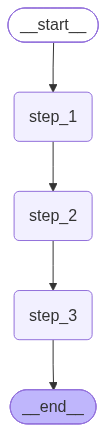

In [53]:
graph

In [54]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging...
❌ Kernel manually interrupted (crash simulated).


In [55]:
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)


🔁 Re-running the graph to demonstrate fault tolerance...
⏳ Step 2 hanging...
✅ Step 3 executed

✅ Final State: {'input': 'start', 'step1': 'done', 'step2': 'done', 'done': True}


In [56]:
list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done', 'done': True}, next=(), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5765-36d0-6b18-8003-822a8bfc476e'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-31T21:59:20.770833+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5765-36cf-61a0-8002-3f59ca247eff'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step_3',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5765-36cf-61a0-8002-3f59ca247eff'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-31T21:59:20.770170+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d5764-b232-6816-8001-591e3e52be21'}}, tasks=(PregelTask(id='019ddb5e-87a2-3a65-eb